In [1]:
# === Imports ===
import pickle
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import sys

from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from scipy.stats import binned_statistic, median_abs_deviation
from scipy.interpolate import UnivariateSpline, LSQUnivariateSpline
from scipy.interpolate import interp1d

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
def gmi_diam_zang(color, i, d):
    '''
    Calculate stellar radii from g-i and i, based on Zang 2018
    https://ui.adsabs.harvard.edu/abs/2018PASP..130j4401Z/abstract
    ---
    color : (g-i) color for the stars
    i : i-band magnitude for the stars
    d : distance to the stars in kpc
    '''
    # log_theta = c0 + c1(X-Xp)
    X = color
    log_diam_0 = 0.920 + 0.316*(X-0.576)
    log_diam_g = log_diam_0 - 0.2*i
    stellar_diams = 10**log_diam_g # in mas
    
    # r = diam/2*w
    r_sol = 0.00465 # AU/R_sol
    w = 1/d # parallax, [mas]
    rads = stellar_diams/(2*w) # AU
    rads_sol = rads/r_sol # AU/(AU/R_sol) = AU*R_sol/AU = R_sol
    
    return stellar_diams, rads_sol

In [3]:
# === Isochrone Filter and Radii Calculation Function ===

'''
This function takes the name of your isochrone file and a log(age), filters the isochrone file for the appropriate 
    age, and calculates the stellar radii from the luminosity, temperature, etc.

The age of the bulge is another complicated question, but we've been using 10^10 years as the age. 
    So log(age) should just be 10.
'''
def load_iso(isofile,logages_):
    # these are just column numbers
    cRadius=0
    cMass=3
    cMini=2
    cMI=13
    cMTESS=-2
    cMGaia=-5
    cLum=6
    cTeff=4
    cAge=1
    logages = logages_
    
    # if you want multiple ages, give them as a list and this will keep all of them. Otherwise just give a single one.
    if isinstance(logages_,list):
        logages = np.array(logages_)
    elif not isinstance(logages_,np.ndarray):
        logages = np.array([logages])
    
    # Load isochrone, skipping rows that just have comments
    iso = pd.read_csv(isofile, sep='\\s+', header=None, skiprows=13, engine='python', comment='#')
                                                                                            
    #Replace the idx column with the radii                                                                  
    iso.iloc[:,0] = 10**(0.5*iso.iloc[:,cLum]-2*(iso.iloc[:,cTeff]-np.log10(5777.0)))
            
    # this does the actual filtering for the age(s) you want
    ret = []
    for i, logage in enumerate(logages):
        ret.append(iso[(iso.iloc[:,-1] <= 4.0) & (np.abs(iso.iloc[:,cAge]-logage)<0.001)])
    if len(ret)==1:
        ret = ret[0]
    
    return ret

In [4]:
# === Load in MISHAPS File ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_N10.cmd.calibrate_ps"
contents = pd.read_csv(catalog_path, header = None, sep = '\\s+')

# === Apply Column Headers ===
column_labels = ['ID', 'RA_z', 'Dec_z', 'ID_z', 'X_z', 'Y_z', 'mis_z', 'mis_z_err', 'Sky_z', 'qflag_z', '?1z', '?2z',
       'RA_r', 'Dec_r', 'ID_r', 'X_r', 'Y_r', 'mis_r', 'mis_r_err', 'Sky_r', 'qflag_r', '?1r', '?2r',
       'RA_g', 'Dec_g', 'ID_g', 'X_g', 'Y_g', 'mis_g', 'mis_g_err', 'Sky_g', 'qflag_g', '?1g', '?2g',
       'RA_i', 'Dec_i', 'ID_i', 'X_i', 'Y_i', 'mis_i', 'mis_i_err', 'Sky_i', 'qflag_i', '?1i', '?2i',
       'RA_Y', 'Dec_Y', 'ID_Y', 'X_Y', 'Y_Y', 'mis_Y', 'mis_Y_err', 'Sky_Y', 'qflag_Y', '?1Y', '?2Y']
              
contents.columns = column_labels

In [5]:
# === Apply Quality Filters ===
print(contents.shape)

# mask_flags = (contents['qflag_i'] == 1) & (contents['qflag_g'] == 1) & (contents['qflag_r'] == 1) & (contents['qflag_z'] == 1)
mask_err = (contents['mis_g_err'] < 0.2) & (contents['mis_i_err'] < 0.2) & (contents['mis_r_err'] < 0.2) & (contents['mis_z_err'] < 0.2)
# mask_sky = (contents["Sky_g"] < 25) & (contents["Sky_i"] < 170) & (contents["Sky_r"] < 800) & (contents["Sky_z"] < 3500)

# print(contents[['qflag_g', 'qflag_i', 'mis_g_err', 'mis_i_err', 'Sky_g', 'Sky_i']].describe(include='all'))

# combined_mask = mask_flags #& mask_err & mask_sky
filtered_contents = contents[mask_err]

print(filtered_contents.shape)

(127748, 56)
(45515, 56)


In [6]:
r = filtered_contents.loc[:, 'mis_r']
i = filtered_contents.loc[:, 'mis_i']
g = filtered_contents.loc[:, 'mis_g']

A_r = 0.7798146039198492
A_i = 0.5674468654068576

E_gmi_i = 0.4932267870613054
gmi = g - i

r_dred = r - A_r
i_dred = i - A_i
gmi_dred = gmi - E_gmi_i

In [7]:
## JUST SET SOME CONSTANT VARIABLES
isodir = "/home/bernthold.17/SURP2025/Transforms/MIST_v1.2_vvcrit0.4_PanSTARRS"
logage = 10
d_iso = 8000 # pc

mag1 = 'i' # band you want on magnitude axes
mag2 = 'r'
c1 = 'g' # first band in color
c2 = 'i' # second band in color
c3 = 'r'
c4 = 'z'

iso_cols = ['Radius_Estimate', 'log10_isochrone_age_yr', 'initial_mass', 'star_mass', 'log_Teff', 'log_g', 'log_L', '[Fe/H]_init',
            '[Fe/H]', 'PS_g', 'PS_r', 'PS_i', 'PS_z', 'PS_y', 'PS_w', 'PS_open', 'phase']

fehs = ['m2.50', 'm2.00', 'm1.75', 'm1.50', 'm1.25', 'm1.00', 'm0.75', 'm0.50', 'm0.25', 'p0.00', 'p0.25', 'p0.50']
print(len(fehs))

12


In [8]:
## For colors and linestyles, use same length as number of isochrones, change as you like
clrs = ['#125A56', '#125A56', '#238F9D', '#238F9D', '#60BCE9','#60BCE9', '#F9D576', '#F9D576', '#E94C1F', '#E94C1F', '#A01813', '#A01813']
lines = ['-', '--', '-', '--', '-', '--', '-', '--', '-', '--', '-', '--']
print(len(clrs))
print(len(lines))

fonts = 24 #fontsize, just so you don't have to change it in every label command

12
12


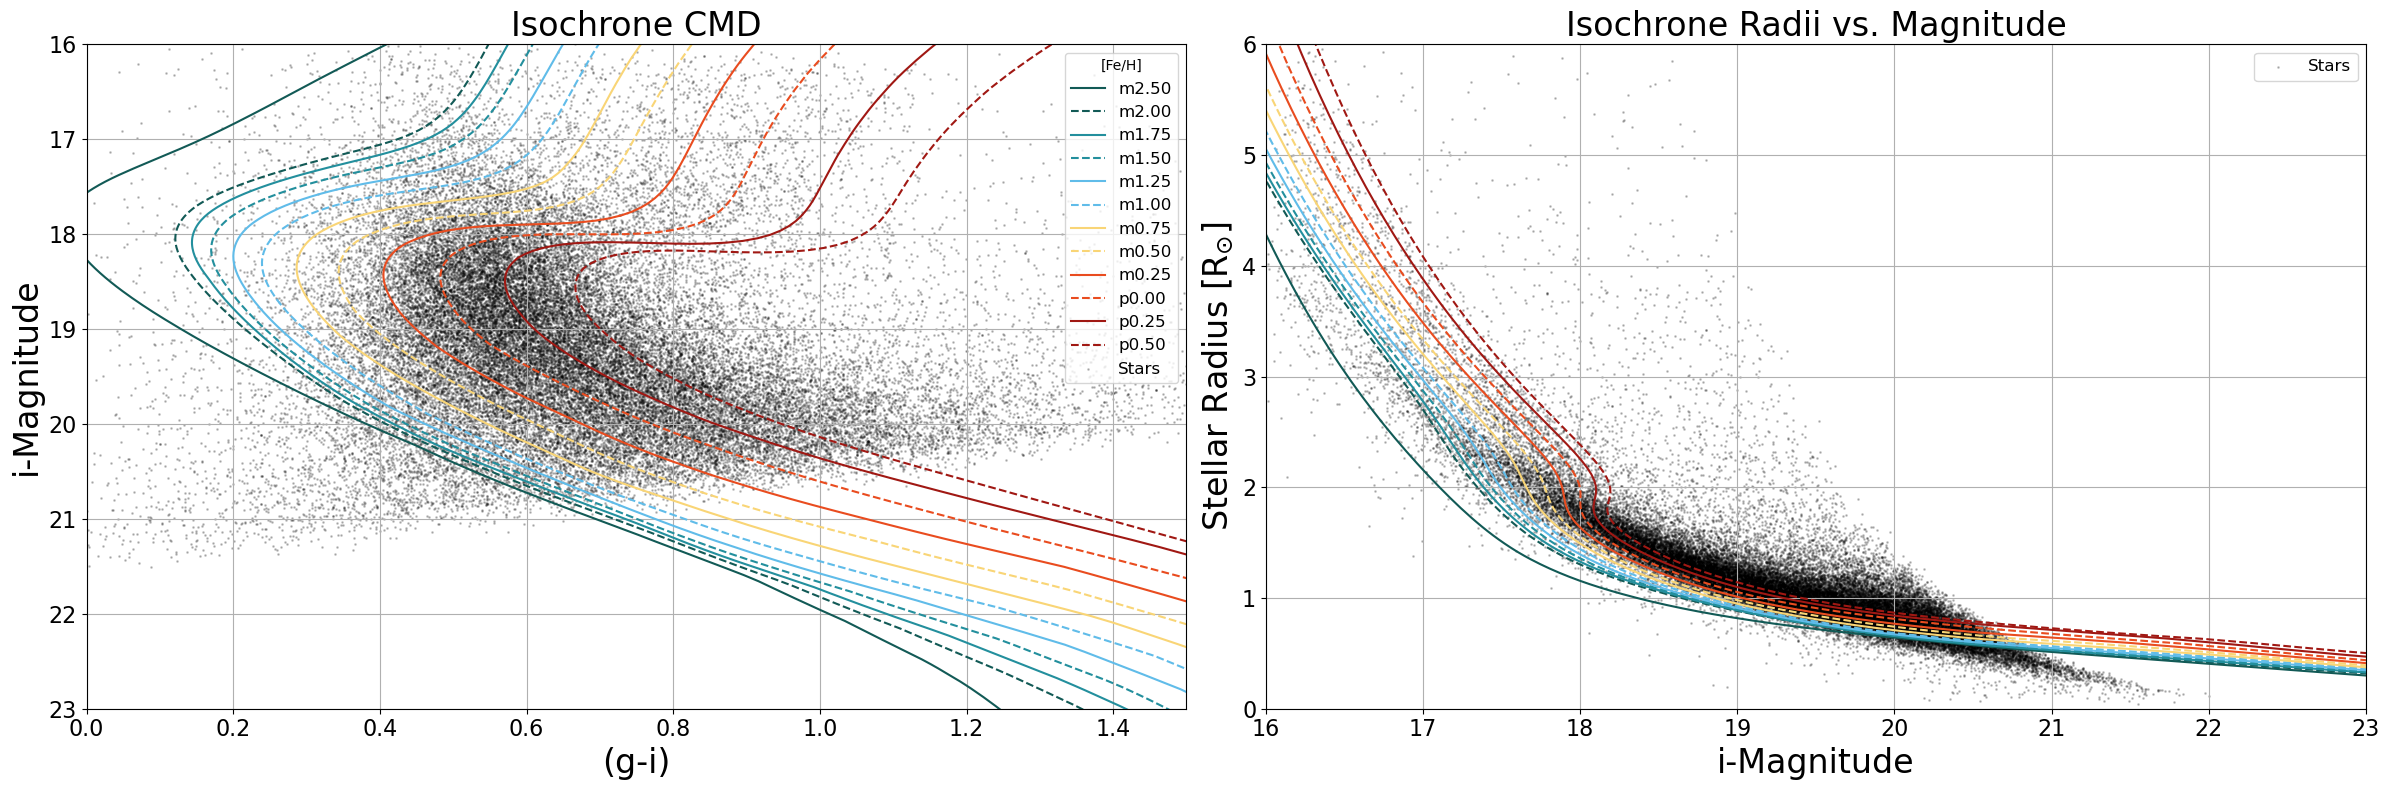

In [13]:
# === Calculate stellar radii using Zang (2018) method ===
diameters, radius = gmi_diam_zang(gmi_dred, i_dred, 8.0)  # distance in kpc

# === Create Plot ===
fig, axs = plt.subplots(1, 2, figsize=(24, 8))
axs[0].set_title('Isochrone CMD', fontsize=fonts)
axs[1].set_title('Isochrone Radii vs. Magnitude', fontsize=fonts)

# === Plot Isochrones ===
for idx, feh in enumerate(fehs):
    isofile = f"{isodir}/MIST_v1.2_feh_{feh}_afe_p0.0_vvcrit0.4_PanSTARRS.iso.cmd"
    iso = load_iso(isofile, logage)
    iso.columns = iso_cols

    ps_iso = {
        'g': iso['PS_g'] + 5 * np.log10(d_iso) - 5,
        'r': iso['PS_r'] + 5 * np.log10(d_iso) - 5,
        'i': iso['PS_i'] + 5 * np.log10(d_iso) - 5,
        'z': iso['PS_z'] + 5 * np.log10(d_iso) - 5,
    }

    axs[0].plot(ps_iso[c1] - ps_iso[c2], ps_iso[mag1], c=clrs[idx], ls=lines[idx], label=feh)
    axs[1].plot(ps_iso[mag1], iso['Radius_Estimate'], c=clrs[idx], ls=lines[idx])

# === Plot Stars ===
axs[0].scatter(gmi_dred, i_dred, c='k', label='Stars', alpha=0.2, s=1)
axs[1].scatter(i_dred, radius, c='k', label='Stars', alpha=0.2, s=1)

# === Format CMD ===
axs[0].set_xlabel(f"({c1}-{c2})", fontsize=fonts)
axs[0].set_xlim(0.0, 1.5)
axs[0].set_ylabel(f"{mag1}-Magnitude", fontsize=fonts)
axs[0].set_ylim(16.0, 23.0)
axs[0].invert_yaxis()
axs[0].tick_params(axis='both', which='major', labelsize=16)
axs[0].grid()
axs[0].legend(fontsize=12, title='[Fe/H]')

# === Format Radius-Mag plot ===
axs[1].set_xlabel(f"{mag1}-Magnitude", fontsize=fonts)
axs[1].set_xlim(16.0, 23.0)
axs[1].set_ylabel(r"Stellar Radius [R$_{\odot}$]", fontsize=fonts)
axs[1].set_ylim(0.0, 6.0)
axs[1].tick_params(axis='both', which='major', labelsize=16)
axs[1].grid()
axs[1].legend(fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Look into literature about a good age for the stars to be in the isochrones. 
# 10 Gyrs is a good estimate, but there could be better.